# 01 · Exploratory data analysis

IBM Telco Customer Churn: who leaves, and what separates them from who stays?

The data is loaded through `churn.data.load_data()`, so every row here has already passed the Pandera schema.

In [1]:
import sys
sys.path.append('../src')

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from churn.config import CATEGORICAL_COLS, NUMERIC_COLS, TARGET
from churn.data import load_data

sns.set_theme(style='whitegrid')
df = load_data()
df.shape

(7043, 21)

## 1. Class balance

About 26.5% of customers churn. That's why accuracy is a poor headline metric: a model that always says "stays" gets ~73.5%.

In [2]:
df[TARGET].value_counts(normalize=True).rename({0: 'stayed', 1: 'churned'}).round(3)

Churn
stayed     0.735
churned    0.265
Name: proportion, dtype: float64

## 2. Data quality notes

- `TotalCharges` was text in the raw file, blank for the 11 customers with tenure 0. `clean()` sets those to 0.
- `SeniorCitizen` was 0/1 while every other flag is Yes/No; it's now Yes/No.
- No other missing values.

In [3]:
df.isna().sum().sum(), (df['tenure'] == 0).sum()

(np.int64(0), np.int64(11))

## 3. Churn rate by category

Sorted by how much the churn rate varies within each feature.

In [4]:
rates = []
for col in CATEGORICAL_COLS:
    r = df.groupby(col)[TARGET].agg(['mean', 'size'])
    r['feature'] = col
    rates.append(r.reset_index().rename(columns={col: 'value'}))
rates = pd.concat(rates)
spread = rates.groupby('feature')['mean'].agg(lambda s: s.max() - s.min()).sort_values(ascending=False)
spread.round(3)

feature
Contract            0.399
InternetService     0.345
OnlineSecurity      0.344
TechSupport         0.342
OnlineBackup        0.325
DeviceProtection    0.317
PaymentMethod       0.300
StreamingMovies     0.263
StreamingTV         0.261
SeniorCitizen       0.181
PaperlessBilling    0.172
Dependents          0.158
Partner             0.133
MultipleLines       0.037
PhoneService        0.018
gender              0.008
Name: mean, dtype: float64

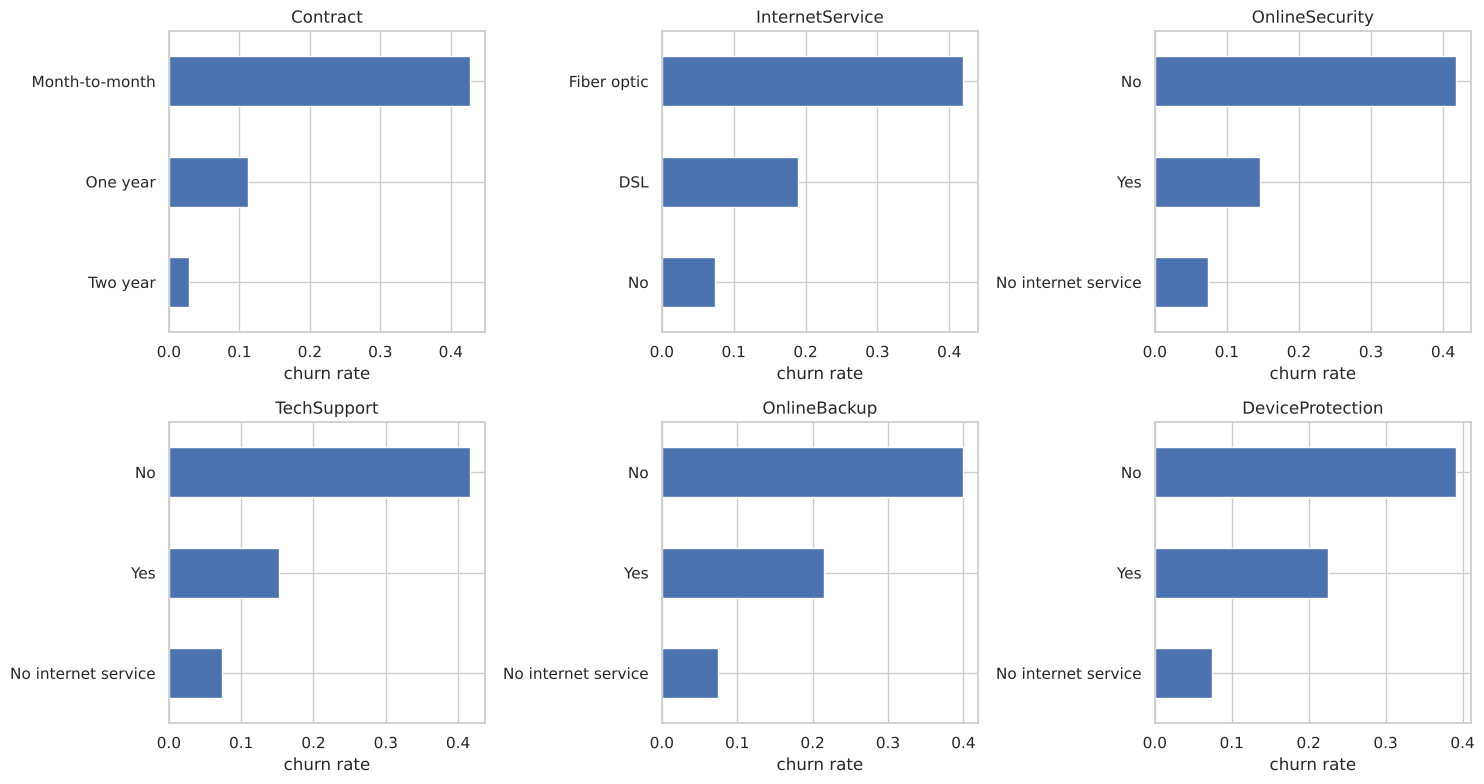

In [5]:
top = spread.index[:6]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, top):
    df.groupby(col)[TARGET].mean().sort_values().plot.barh(ax=ax, color='#4C72B0')
    ax.set_title(col)
    ax.set_xlabel('churn rate')
    ax.set_ylabel('')
plt.tight_layout()
plt.savefig('../reports/figures/churn_by_category.png', dpi=120)

## 4. Numeric features

Churners are concentrated in the first months of tenure and pay higher monthly charges.

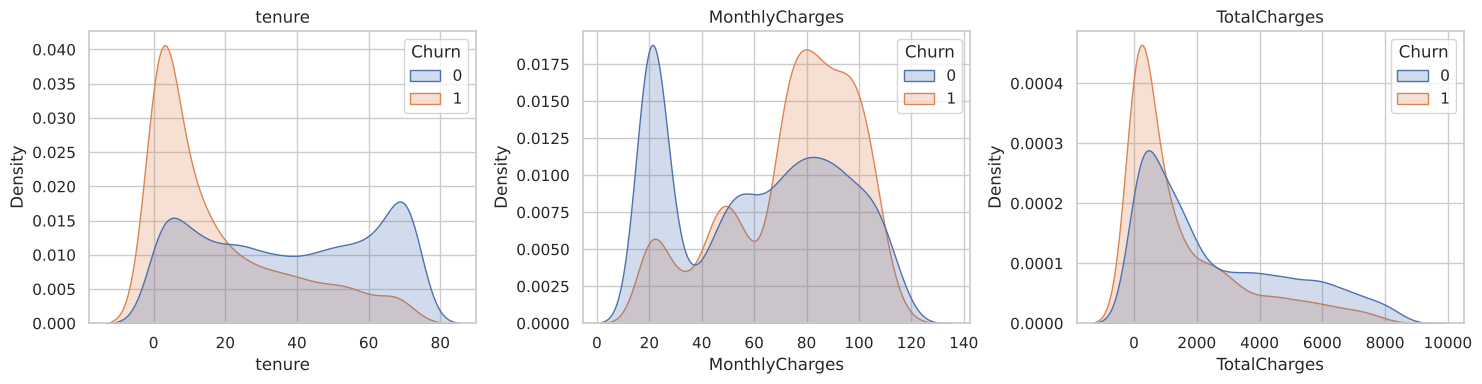

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, NUMERIC_COLS):
    sns.kdeplot(data=df, x=col, hue=TARGET, common_norm=False, fill=True, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.savefig('../reports/figures/numeric_distributions.png', dpi=120)

In [7]:
df.groupby(TARGET)[NUMERIC_COLS].median().rename({0: 'stayed', 1: 'churned'})

,tenure,MonthlyCharges,TotalCharges
Churn,,,
stayed,38.0,64.425,1679.525
churned,10.0,79.650,703.550


## 5. Contract × tenure

Month-to-month customers in their first year are the highest-risk group, a strong hint for feature engineering (tenure buckets, contract interactions).

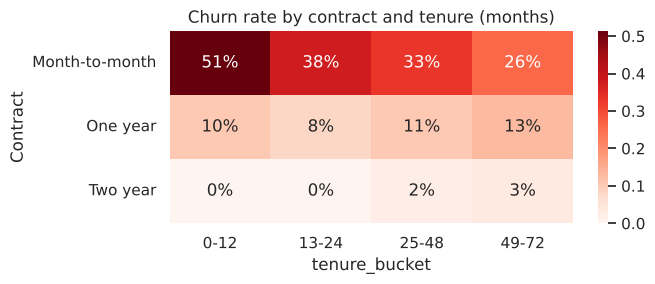

In [8]:
df['tenure_bucket'] = pd.cut(df['tenure'], [-1, 12, 24, 48, 72], labels=['0-12', '13-24', '25-48', '49-72'])
pivot = df.pivot_table(index='Contract', columns='tenure_bucket', values=TARGET, aggfunc='mean', observed=True)
plt.figure(figsize=(7, 3))
sns.heatmap(pivot, annot=True, fmt='.0%', cmap='Reds')
plt.title('Churn rate by contract and tenure (months)')
plt.tight_layout()
plt.savefig('../reports/figures/contract_tenure_heatmap.png', dpi=120)

## 6. Takeaways for modelling

1. Contract type, tenure, internet service (fibre especially) and the lack of tech support / online security carry the most signal.
2. Payment by electronic check stands out among payment methods.
3. Feature ideas for milestone 3: tenure buckets, count of add-on services, `TotalCharges / tenure` vs `MonthlyCharges` (price changes), contract × tenure interaction.
4. Classes are imbalanced (~26.5% churn), so we compare models on ROC-AUC, PR-AUC, recall on churners and "churners caught in the top 20%".